### Import et chemin du fichier

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = "data/"
SUBSET = "FD002"

Chargement du jeu d'entraînement

In [4]:
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv(f"{DATA_DIR}train_{SUBSET}.txt", sep=r"\s+", header=None, names=cols)
print(train.shape)
train.head()

(53759, 26)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


- unit -> identifiant du moteur
- cycle -> numéro de vol (de 1 jusqu'à la panne)
- op1, op2, op3 -> conditions de fonctionnement (altitude, nombre de Mach et angle de manette de poussée)
- s1 à s21 sont les mesures capteurs (températures, pression, vitesses, etc) C'est la réponse du moteur


### Combien de moteurs, quelle durée de vie ?

In [5]:
print("Moteurs :", train["unit"].nunique())

durees = train.groupby("unit")["cycle"].max()
print(durees.describe())
print(train.isna().sum().sum(), "Valeurs manquantes")

Moteurs : 260
count    260.000000
mean     206.765385
std       46.782198
min      128.000000
25%      174.000000
50%      199.000000
75%      230.250000
max      378.000000
Name: cycle, dtype: float64
0 Valeurs manquantes


- 260 moteurs
- Aucune valeur manquante
- Durée de vie très dispersées: de 128 à 378 cycles avec une moyenne d'environ 207 et un écart-type de 47

Un moteur peut donc durer presque 3 fois plus longtemps qu'un autre

### Combien de régimes de fonctionnement ?

In [7]:
regimes = train[["op1", "op2", "op3"]].round({"op1": 0, "op2": 2, "op3": 0})

print(regimes.value_counts())

op1   op2   op3  
42.0  0.84  100.0    13458
20.0  0.70  100.0     8122
10.0  0.25  100.0     8096
0.0   0.00  100.0     8044
35.0  0.84  100.0     8037
25.0  0.62  60.0      8002
Name: count, dtype: int64


Nous pouvons identifier 6 régimes de fonctionnement

#### Donner un numéro de régime à chaque ligne

In [8]:
from sklearn.cluster import KMeans

conditions = train[["op1", "op2", "op3"]]
km = KMeans(n_clusters= 6, n_init=10, random_state = 0).fit(conditions)
train["regime"]= km.labels_
print(train["regime"].value_counts().sort_index())

regime
0    13458
1     8096
2     8002
3     8044
4     8037
5     8122
Name: count, dtype: int64


Les effectifs correspondent parfaitement, la colonne regime est prête

### Quels capteurs sont utiles ?

In [9]:
capteurs = [f"s{i}" for i in range(1, 22)]
print(train.groupby("regime")[capteurs].std().round(3).T)

regime       0       1       2       3       4       5
s1       0.000   0.000   0.000   0.000   0.000   0.000
s2       0.433   0.474   0.358   0.496   0.439   0.463
s3       5.633   5.790   5.281   6.022   5.616   5.783
s4       7.637   8.457   6.809   8.937   7.402   7.794
s5       0.000   0.000   0.000   0.000   0.000   0.000
s6       0.005   0.005   0.004   0.001   0.002   0.005
s7       0.439   0.671   0.448   0.868   0.476   0.606
s8       0.300   0.094   0.262   0.071   0.279   0.126
s9      18.014  18.251  14.100  19.213  16.989  17.211
s10      0.002   0.000   0.001   0.000   0.002   0.004
s11      0.239   0.252   0.208   0.264   0.230   0.238
s12      0.341   0.535   0.344   0.735   0.376   0.497
s13      0.323   0.098   0.277   0.071   0.300   0.130
s14     16.478  16.021  13.040  16.542  15.435  15.126
s15      0.038   0.038   0.043   0.037   0.038   0.039
s16      0.000   0.000   0.000   0.000   0.000   0.004
s17      1.409   1.489   1.293   1.521   1.404   1.466
s18      0

Un capteur dont l'écart-type dans tous les régimes est proche de 0 dans tous les régimes ne varie pas. Il n'apporte donc aucune information sur la santé du moteur. Ils seront donc écartés.
Il s'agit ici de s1, s5, s18, s19

Certains ont un écrat-type quasi-nul: s6, s10 et s16
On vérifie donc leur valeur avant de les écarter

In [10]:
douteux = ["s1", "s5", "s6", "s10", "s16", "s18", "s19"]
print(train.groupby("regime")[douteux].mean().round(3).T)

regime         0         1         2        3        4         5
s1       445.000   489.050   462.540   518.67   449.44   491.190
s5         3.910    10.520     7.050    14.62     5.48     9.350
s6         5.716    15.493     9.028    21.61     8.00    13.657
s10        1.020     1.260     0.940     1.30     1.02     1.078
s16        0.020     0.030     0.020     0.03     0.02     0.022
s18     2212.000  2319.000  1915.000  2388.00  2223.00  2324.000
s19      100.000   100.000    84.930   100.00   100.00   100.000


In [11]:
a_retirer = ["s1", "s5", "s6", "s10", "s16", "s18", "s19"]
capteurs_utiles = [s for s in capteurs if s not in a_retirer]

print(len(capteurs_utiles), capteurs_utiles)

14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


Cette dernière liste servira pour le reste du projet: normalisation, baseline, modèles.

### Normalisation de chaque capteur à l'intérieur de son régime

In [13]:
ref = train[train["cycle"] <= 30]
moy = ref.groupby("regime")[capteurs_utiles].mean()
ecart = ref.groupby("regime")[capteurs_utiles].std()

norm = (train[capteurs_utiles] - moy.loc[train["regime"]].values) / ecart.loc[train["regime"]].values
print(norm.loc[ref.index].agg(["mean", "std"]).round(2))


       s2   s3   s4   s7   s8   s9  s11  s12  s13  s14  s15  s17  s20  s21
mean  0.0 -0.0  0.0  0.0  0.0 -0.0 -0.0 -0.0  0.0 -0.0 -0.0 -0.0 -0.0 -0.0
std   1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0  1.0


Moyennes et écart-types calculés uniquement sur les 30 prmeiers cycles (moteur supposé sain)
Ces statistiques sont apprises sur le train.

#### Voir l'effet sur un moteur

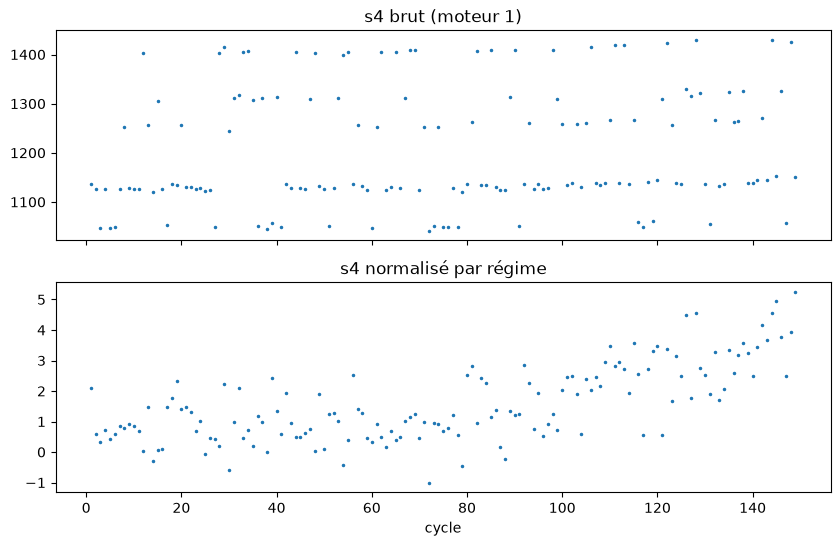

In [15]:
u = train["unit"] == 1

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(train.loc[u, "cycle"], train.loc[u, "s4"], ".", markersize=3)
ax[0].set_title("s4 brut (moteur 1)")
ax[1].plot(train.loc[u, "cycle"], norm.loc[u, "s4"], ".", markersize=3)
ax[1].set_title("s4 normalisé par régime")
ax[1].set_xlabel("cycle")
plt.show()

S4 correspond à la température de sortie de la turbine basse pression (T50) dans la nomenclature NASA.

En haut (brut) -> Des bandes horizontales superposées, une par régime. La tendance de dégradation est noyée dedans

En bas (normalisé) -> Les bandes sont foncues en un seul nuage: plat au début, puis dérive vers le haut. C'est le signe de la dégradation attendue sur la turbine.

On note toutefois un bruit important, il faut lisser dans le temps.



### Lisser les 14 capteurs d'un moteur

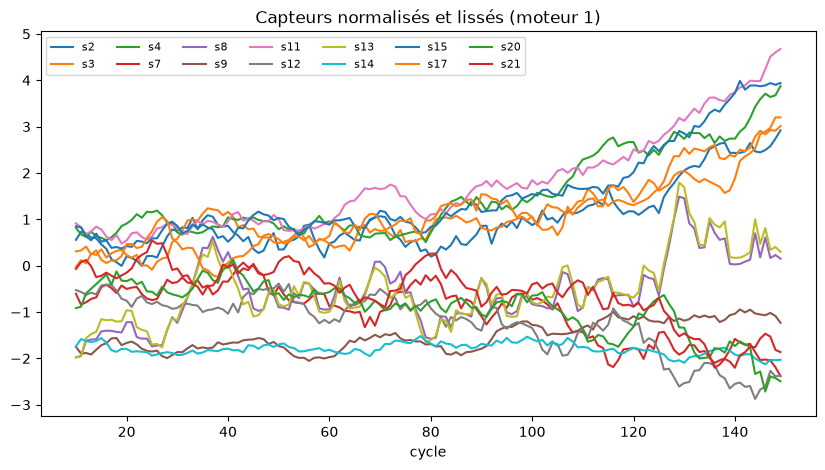

In [16]:
lisse = norm.loc[u, capteurs_utiles].rolling(10).mean()
plt.figure(figsize=(10, 5))
for s in capteurs_utiles:
    plt.plot(train.loc[u, "cycle"], lisse[s], label=s)
plt.legend(ncol=7, fontsize=8)
plt.xlabel("cycle")
plt.title("Capteurs normalisés et lissés (moteur 1)")
plt.show()

Après lissage sur 10 cycles, certains capteurs montent (jusqu'à +3 à +4,7 écarts-types), d'autres descendent (jusqu'à -2 à -3), d'autres restent quasi plats. Les couleurs se répètent, donc ce graphique ne permet pas d'identifier chaque courbe avec certitude.

Plusieurs capteurs portent un signal de dégradation, avec des signes opposés. La dérive devient visible vers le cycle 80-100 pour ce moteur. Ce graphique sert à avoir une vue d'ensemble ; l'analyse capteur par capteur est faite juste après.

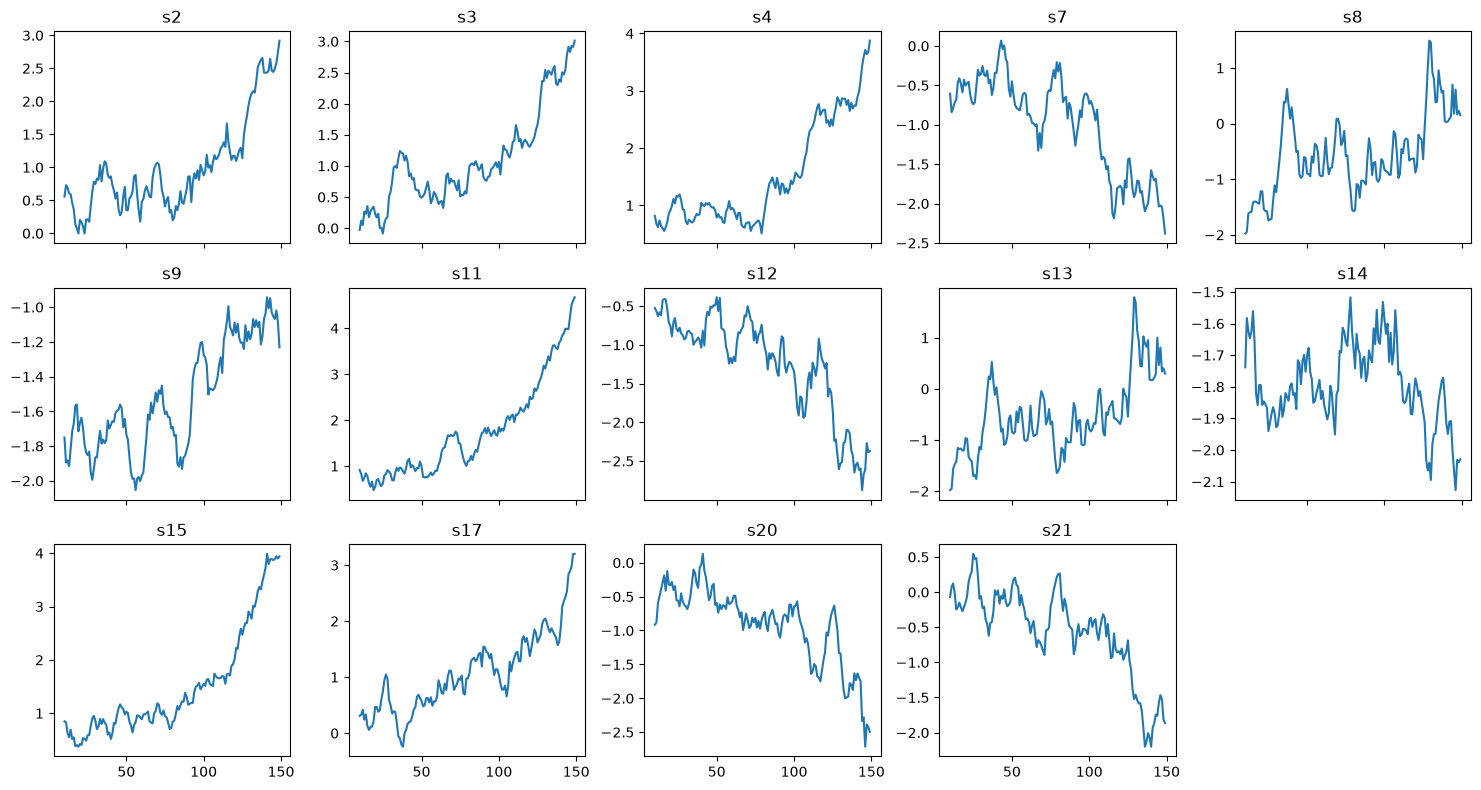

In [17]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8), sharex=True)
for ax, s in zip(axes.ravel(), capteurs_utiles):
    ax.plot(train.loc[u, "cycle"], lisse[s])
    ax.set_title(s)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

 Capteurs à tendance nette : s11, s15, s4, s2, s3, s17 (montent) ; s12, s20, s21, s7 (descendent). s9 monte légèrement avec de fortes oscillations. s14 reste plat. s8 et s13 sont irréguliers, avec un pic isolé vers le cycle 128. Plusieurs courbes (s2, s3, s4, s11, s15) sont presque plates jusqu'au cycle 100, puis accélèrent.

 Les capteurs à tendance nette sont de bons candidats comme indicateurs de santé. s14, s8 et s13 sont écartés pour l'instant. La dégradation s'accélère en fin de vie : les premiers signes sont faibles, donc détecter tôt est difficile. Attention : chaque graphique a sa propre échelle verticale, et tout ceci ne concerne qu'un seul moteur.

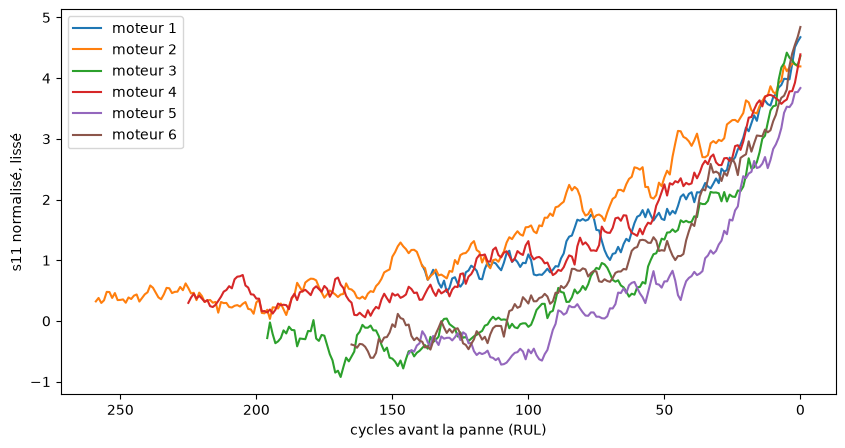

In [18]:
train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
lisse_s11 = norm["s11"].groupby(train["unit"]).transform(lambda x: x.rolling(10).mean())

plt.figure(figsize=(10, 5))
for k in [1, 2, 3, 4, 5, 6]:
    m = train["unit"] == k
    plt.plot(train.loc[m, "rul"], lisse_s11[m], label=f"moteur {k}")
plt.gca().invert_xaxis()
plt.xlabel("cycles avant la panne (RUL)")
plt.ylabel("s11 normalisé, lissé")
plt.legend()
plt.show()

Les 6 moteurs suivent la même forme : s11 reste à peu près plat, puis monte de plus en plus vite et termine entre environ 3,8 et 4,8 écarts-types à la panne. Le moment où la hausse démarre varie : environ 150 à 170 cycles avant la panne pour les moteurs 1, 2 et 4, environ 80 à 100 cycles pour les moteurs 3, 5 et 6. Les niveaux de départ diffèrent aussi légèrement d'un moteur à l'autre.

Le motif de dégradation est cohérent d'un moteur à l'autre, ce qui rend la détection possible. Le niveau atteint en fin de vie est assez stable, ce qui pourrait servir à fixer un seuil. Mais le début du décollage varie beaucoup : un seuil fixe détectera tôt certains moteurs et tard d'autres, d'où l'intérêt d'un seuil adaptatif par moteur. Les différences de niveau de départ suggèrent aussi de normaliser chaque moteur par rapport à ses propres premiers cycles.

### Qu'est-ce qu'une panne imminente ?

In [19]:
for N in [10, 20, 30, 50]:
    part = (train["rul"] <= N).mean()
    print(N, round(part * 100, 1), "%")

10 5.3 %
20 10.2 %
30 15.0 %
50 24.7 %


Choix du N:
- 10: On a 5% de positifs, trop peu. L'alerte arriverait tard, quand le signal est déjà évident, peu de temps pour l'action
- 50: 25% de positifs, trop large. Les moteurs seraient "imminents" trop facilement, ce qui produirait de fausse alertes
- 30: 15% de positifs. Bon compromis. Le signal est déjà net 30 cycles avant la panne sur les 6 moteurs, ca laisse la marge de planifier une intervention.

In [20]:
N=30
train["imminent"]= (train["rul"] <= N).astype(int)
print(train["imminent"].value_counts())

imminent
0    45699
1     8060
Name: count, dtype: int64


Cette étiquette ne sert qu'à évaluer les détecteurs et à entraîner XGBoost. 

### Z-score glissant causal par moteur

In [21]:
w = 10
lisse_causal = (
    norm.groupby(train["unit"])
    .rolling(w, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)

print(lisse_causal.shape)

(53759, 14)


On cherche ici à lisser le signal sans tricher.
Les capteurs sont bruités, donc on moyenne chaque capteur sur ces 10 derniers cycles, moteur par moteur.
Seul le passé est utilisé, comme dans un vrai système qui ne connaît pas le futur.

In [23]:
score = lisse_causal.abs().mean(axis=1)
print(score.groupby(train["imminent"]).describe())

            count      mean       std       min       25%       50%       75%  \
imminent                                                                        
0         45699.0  0.730447  0.438044  0.087713  0.417431  0.622477  0.908012   
1          8060.0  2.449718  0.852055  0.687943  1.850427  2.290864  2.878657   

               max  
imminent            
0         3.731335  
1         6.259057  


Un seul chiffre par cycle. On a 14 capteurs, mais pour déclencher une alerte il est plus simple d'avoir un seul chiffre. Chaque capeteur est déjà exprimé en écart-type par rapport à l'état sain.
On a pris la valeur absolue de chaque capteur, puis la moyenne.
On obtient un score de dégradation : plus il est grand, plus le moteur s'éloigne de son état sain

In [24]:
for seuil in [1.0, 1.5, 2.0, 2.5]:
    alerte = score > seuil
    taux_detection = alerte[train["imminent"] == 1 ].mean()
    taux_fausses = alerte[train["imminent"] == 0].mean()
    print(seuil, round(taux_detection * 100, 1), round(taux_fausses * 100, 1))

1.0 99.3 20.2
1.5 90.2 6.6
2.0 67.2 2.0
2.5 38.6 0.4


Le seuil de 1.0 ne rate presuqe aucune panne mais un moteur sain déclencherait beaucoup de fausse alerte
Le seuil de 2.5 possède très peu de fausse alarme mais peut rater beacoup d'état imminent
Les seuils de 1.5 et 2.0 peuvent être de juste milieu

On fait le choix du seuil de 1.5 car uen détection manquée coûte plus qu'une fausse alerte

In [25]:
n = 5
brute = (score > 1.5).astype(int)
print("k détéctés avance_moy moteurs_fausses %fausses")
for k in [1, 2, 3, 4, 5]:
    somme = brute.groupby(train["unit"]).rolling(n, min_periods = 1).sum().reset_index(level=0, drop=True)
    persist = somme >= k
    dans_fenetre = persist & (train["imminent"] == 1)
    avant = persist & (train["imminent"] == 0)
    rule_det = train.loc[dans_fenetre].groupby("unit")["rul"].max()
    moteurs_fausses = avant.groupby(train["unit"]).any().sum()
    pct_fausses = avant[train["imminent"] == 0].mean() * 100
    print(k, len(rule_det), round(rule_det.mean(),1), moteurs_fausses, round(pct_fausses,1))

k détéctés avance_moy moteurs_fausses %fausses
1 260 27.2 166 7.1
2 260 26.7 162 6.5
3 260 26.3 153 5.9
4 260 25.9 146 5.4
5 260 25.3 140 4.9


### Baseline 1 : persistance (k alertes sur 5 cycles), seuil = 1,5

Alerte brute si le score de santé dépasse 1,5. Elle est confirmée s'il y a au moins k alertes brutes sur les 5 derniers cycles (méthode causale). « Imminent » = RUL ≤ 30. Une alerte confirmée avant cette fenêtre est comptée comme fausse alarme.

| k | détectés (/260) | avance moy. (cycles) | moteurs avec fausse alarme | % cycles sains en alerte |
|---|---|---|---|---|
| 1 | 260 | 27,2 | 166 | 7,1 |
| 3 | 260 | 26,3 | 153 | 5,9 |
| 5 | 260 | 25,3 | 140 | 4,9 |

**Lecture :** les 260 moteurs sont détectés quel que soit k. Augmenter k fait perdre environ 2 cycles d'avance et réduit peu les fausses alarmes (7,1 % à 4,9 %), mais plus de la moitié des moteurs en ont encore au moins une.

**Limite :** une alerte avant RUL = 30 est peut-être une détection précoce (le décollage des capteurs commence 80 à 170 cycles avant la panne), pas une vraie erreur. À vérifier.

In [26]:
k = 3

somme = brute.groupby(train["unit"]).rolling(n, min_periods=1).sum().reset_index(level=0, drop=True)
persist = somme >= k
avant = persist & (train["imminent"] == 0)
rul_fausse = train.loc[avant].groupby("unit")["rul"].max()
print(rul_fausse.describe())
print((rul_fausse > 60).sum(), (rul_fausse > 100).sum())

count    153.000000
mean      48.823529
std       13.165004
min       31.000000
25%       39.000000
50%       46.000000
75%       56.000000
max       93.000000
Name: rul, dtype: float64
28 0


**Origine des fausses alarmes (k = 3).** Sur les 153 moteurs concernés, la première fausse alarme tombe en médiane à 46 cycles de la panne (75 % à ≤ 56, max 93, aucun au-delà de 100). 28 moteurs seulement dépassent 60. Ces alertes sont donc surtout précoces, juste avant la fenêtre « imminent » (RUL ≤ 30), et non dispersées dans la phase saine. Elles sont pénalisées par la définition stricte de N = 30, et non par un détecteur instable. Hypothèse à confirmer.

In [27]:
k = 3
limite = 60
persist = somme >= k
zone_fausse = train["rul"] > limite
fausses = persist & zone_fausse
moteurs_fausses = fausses.groupby(train["unit"]).any().sum()
pct_fausses = fausses[zone_fausse].mean() * 100
rul_det = train.loc[persist & (train["imminent"] == 1)].groupby("unit")["rul"].max()
print("moteurs avec fausse alarme (RUL >", limite, ") :", moteurs_fausses)
print("% de cycles RUL >", limite, "en alerte :", round(pct_fausses, 2))
print("moteurs détectés (RUL <= 30) :", len(rul_det), "| avance moyenne :", round(rul_det.mean(), 1))

moteurs avec fausse alarme (RUL > 60 ) : 28
% de cycles RUL > 60 en alerte : 0.76
moteurs détectés (RUL <= 30) : 260 | avance moyenne : 26.3


**Évaluation avec zone de tolérance (k = 3, seuil 1,5).** Détection : RUL ≤ 30. Zone neutre : RUL entre 31 et 60. Fausse alarme : RUL > 60. Résultat : 260/260 moteurs détectés, 26,3 cycles d'avance en moyenne ; 28 moteurs avec une fausse alarme (≈ 11 %) ; 0,76 % des cycles RUL > 60 en alerte. Paramètres choisis sur le jeu d'entraînement : à confirmer sur le test.

In [28]:
from sklearn.metrics import average_precision_score, f1_score
masque = ~((train["rul"] > 30) & (train["rul"] <= limite))
y = train.loc[masque, "imminent"]
print("PR-AUC du score :", round(average_precision_score(y, score[masque]), 3))
print("F1 (seuil 1.5, k = 3) :", round(f1_score(y, persist[masque].astype(int)), 3))

PR-AUC du score : 0.983
F1 (seuil 1.5, k = 3) : 0.917


**Référence baseline 1** (zone neutre RUL 31-60 retirée) : PR-AUC du score = 0,983 (hasard ≈ 0,175) ; F1 avec seuil 1,5 et k = 3 = 0,917. Métriques par cycle, calculées sur le train avec des paramètres choisis sur le train : à confirmer sur le test. C'est le chiffre à battre pour la baseline 2 (XGBoost).

## Baseline 2 : XGBoost

**Objectif.** Entraîner un modèle qui prédit, à chaque cycle, si la panne est imminente (RUL ≤ 30), à partir de variables calculées sur les 10 derniers cycles de chaque capteur (moyenne, écart-type, pente). On compare ses résultats à la baseline 1 (PR-AUC = 0,983 ; F1 = 0,917) pour voir si un modèle apprenant fait mieux qu'un simple seuil sur le score de santé.

**Cadre de comparaison.** Découpage par moteur (≈ 80 % entraînement, 20 % validation) pour qu'aucun moteur ne soit des deux côtés, même cible `imminent`, même zone neutre (RUL 31-60) retirée de l'évaluation.

### Construction des variables d'entrée

XGBoost a besoin d'un tableau avec une ligne par cycle et des colonnes qui décrivent l'état du moteur. Pour chacun des 14 capteurs normalisés ('norm'), on résume les 10 derniers cycles du même moteur avec 3 mesures:
- **moyenne** ('_moy'): niveau du capteur par rapport à l'état sain;
- **écart-type** ('_std'): stabilité du signal
- **pente** ('_pen'): tendance, en écart-types par cycle (régression linéaire sur la fenêtre)

On obtient 14 × 3 = 42 variables, stockées pour l'instant dans trois tableaux (`moy_f`, `std_f`, `pen_f`) qui seront assemblés ensuite. Les fenêtres sont **causales** (cycle courant et 9 précédents, jamais le futur) et calculées **moteur par moteur**. Les 9 premiers cycles de chaque moteur n'ont pas de variables (2 340 lignes manquantes, XGBoost sait les gérer) : ils sont dans la phase de référence saine.


In [29]:
g = norm.groupby(train["unit"])
moy_f = g.rolling(w, min_periods=w).mean().reset_index(level=0, drop=True).add_suffix("_moy")
std_f = g.rolling(w, min_periods=w).std().reset_index(level=0, drop=True).add_suffix("_std")

print(moy_f.shape, std_f.shape)
print(moy_f.isna().sum().iloc[0])

(53759, 14) (53759, 14)
2340


In [30]:
t = np.arange(w) - (w-1)/2

def pente(x):
    return np.dot(t, x) / np.dot(t,t)

pen_f = g.rolling(w, min_periods=w).apply(pente, raw=True).reset_index(level = 0, drop = True).add_suffix("_pen")
print(pen_f.shape, pen_f.isna().sum().iloc[0])
print(pen_f["s11_pen"].groupby(train["imminent"]).mean())

(53759, 14) 2340
imminent
0    0.014270
1    0.066287
Name: s11_pen, dtype: float64


La pente moyenne de `s11` est de 0,014 pour les cycles sains et de 0,066 pour les cycles imminents, environ 5 fois plus. C'est cohérent avec la hausse de `s11` observée sur les graphiques.

### Assemblage de la table d'entrée de XGBoost

On regroupe les trois familles de variables (moyenne, écart-type, pente) dans une seule table `X` de 42 colonnes, avec la cible `y` (`imminent`) et le numéro de moteur `groupes`, qui servira au découpage par moteur.

In [31]:
X = pd.concat([moy_f, std_f, pen_f], axis=1)

y = train["imminent"]

groupes = train["unit"]
print(X.shape, y.shape)
print(X.columns[:3].tolist(), X.columns[14:17].tolist(), X.columns[28:31].tolist())

(53759, 42) (53759,)
['s2_moy', 's3_moy', 's4_moy'] ['s2_std', 's3_std', 's4_std'] ['s2_pen', 's3_pen', 's4_pen']


Table d'entrée `X` de 53 759 lignes et 42 colonnes (14 capteurs × moyenne, écart-type, pente), cible `y` de même longueur. L'ordre des colonnes est bien `_moy`, `_std`, `_pen`. Les 9 premiers cycles de chaque moteur restent à `NaN`, ce que XGBoost gère nativement.

### Découpage entraînement / validation par moteur

On sépare les **moteurs** (pas les lignes) en deux groupes: environ 80% pour entraîner XGBoost, 20% pour le valider. deux cycles d'un même moteurse ressemblent beaucoup; si on les répartissait des deux côtés, la validation serait trop facile et le score serait trompeur.

Ici, un moteur est entièrement dans un groupe ou dans l'autre.

In [32]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
idx_train, idx_val = next(gss.split(X, y, groups=groupes))
print(len(idx_train), len(idx_val))
print(groupes.iloc[idx_train].nunique(), groupes.iloc[idx_val].nunique())
print(y.iloc[idx_train].mean(), y.iloc[idx_val].mean())

43029 10730
208 52
0.14985242510864766 0.15023299161230197


208 moteurs (43 029 lignes) pour l'entraînement et 52 moteurs (10 730 lignes) pour la validation, aucun moteur des deux côtés. La proportion de cycles imminents est identique dans les deux groupes (≈ 15,0 %), donc les deux jeux sont comparables.

### Entraînement de XGBoost

On entraîne XGBoost sur les 208 moteurs d'entraînement pour prédire 'imminent' à partir des 42 variables, puis on calcule, pour les 52 moteurs de validation, la probabilité de panne imminente de chaque cycle.

In [33]:
from xgboost import XGBClassifier
modele = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,random_state=0)
modele.fit(X.iloc[idx_train], y.iloc[idx_train])
proba_val = modele.predict_proba(X.iloc[idx_val])[:,1]
print(proba_val.shape, round(proba_val.min(),3), round(proba_val.max(), 3))

(10730,) 0.0 1.0


XGBoost est entraîné sur les 208 moteurs d'entraînement et produit une probabilité de panne imminente pour chacun des 10 730 cycles de validation (52 moteurs). Les probabilités vont de 0 à 1 (valeurs arrondies à 3 décimales) : le modèle est très tranché sur une partie des cycles.

### Evaluation de XGBoost et comparaison avec la baseline 1

On mesure la PR-AUC et le F1 de XGBoost sur les 52 moteurs de validation, avec la même zone neutre (RUL 31-60) retirée, puis on recalcule la baseline 1 sur ces mêmes moteurs pour comparer à données identiques.

In [34]:
val = train.iloc[idx_val]
masque_val = ~((val["rul"] > 30) & (val["rul"] <= limite))
y_val = val.loc[masque_val, "imminent"]
p_xgb = pd.Series(proba_val, index=val.index)[masque_val]
print("XGBoost    PR-AUC :", round(average_precision_score(y_val, p_xgb), 3))
print("XGBoost    F1 (seuil 0.5) :", round(f1_score(y_val, (p_xgb > 0.5).astype(int)), 3))
print("Baseline 1 PR-AUC :", round(average_precision_score(y_val, score[val.index][masque_val]), 3))
print("Baseline 1 F1 (1.5, k=3) :", round(f1_score(y_val, persist[val.index][masque_val].astype(int)), 3))

XGBoost    PR-AUC : 0.995
XGBoost    F1 (seuil 0.5) : 0.917
Baseline 1 PR-AUC : 0.993
Baseline 1 F1 (1.5, k=3) : 0.946


**Comparaison sur les 52 moteurs de validation (zone neutre retirée) :**

| | PR-AUC | F1 |
|---|---|---|
| XGBoost (seuil 0,5) | 0,995 | 0,917 |
| Baseline 1 (seuil 1,5, k = 3) | 0,993 | 0,946 |

**Lecture :** la qualité du score est quasi identique (0,995 contre 0,993). Pour le F1, la baseline 1 est meilleure (0,946 contre 0,917), mais elle utilise une persistance que XGBoost n'a pas ici, et ses paramètres ont été choisis sur le train. Avec 52 moteurs, ces écarts ne permettent pas de désigner un gagnant. Le simple score de santé est déjà très compétitif.